In [10]:
%load_ext autoreload
%autoreload 2
import sys
from sc_foi.bbq.bbq_circuit_fitting import BlackBoxAdmittanceModel, TwoCavityOneCouplerModel

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [11]:
import os
import numpy as np
from lmfit import create_params

# Fitting two modes

In [12]:
ljs = np.logspace(np.log10(1e-2 * 1e-9), np.log10(1e4 * 1e-9), 200)
bbq_am_two = BlackBoxAdmittanceModel(admittance_filename="../../data/ydata_open_circuit_mumachined_degenerate.csv",
                                ljs=ljs, n_modes=2)

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.
findfont: Failed to find font weight medium for DejaVu Sans, now using 400.
findfont: Failed to find font weight medium for DejaVu Sans, now using 400.
findfont: Failed to find font weight medium for STIXGeneral, now using 400.
findfont: Failed to find font weight medium for STIXGeneral, now using 400.
findfont: Failed to find font weight medium for STIXNonUnicode, now using 400.
findfont: Failed to find font weight medium for STIXNonUnicode, now using 400.
findfont: Failed to find font weight medium for STIXSizeOneSym, now using 400.
findfont: Failed to find font weight medium for STIXSizeTwoSym, now using 400.
findfont: Failed to find font weight medium for STIXSizeThreeSym, now using 400.
findfont: Failed to find font weight medium for STIXSizeFourSym, now using 400.
findfont: Failed to find font weight medium for STIXSizeFiveSym, now using 400.
findfont: Failed to find font weight medium for cmmi10, now usi

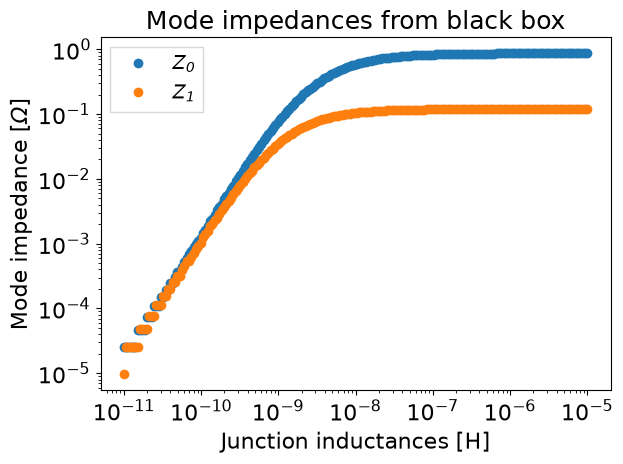

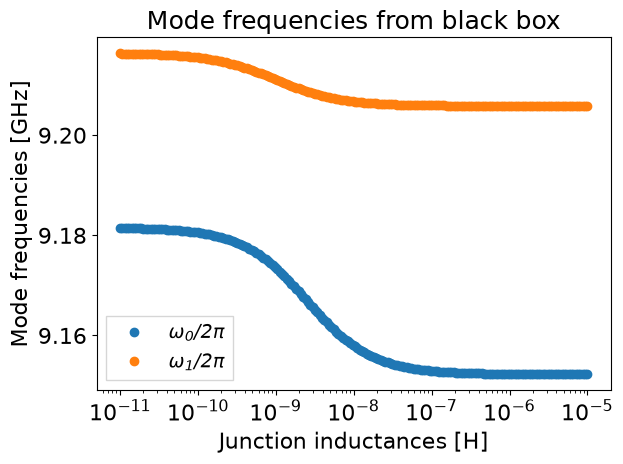

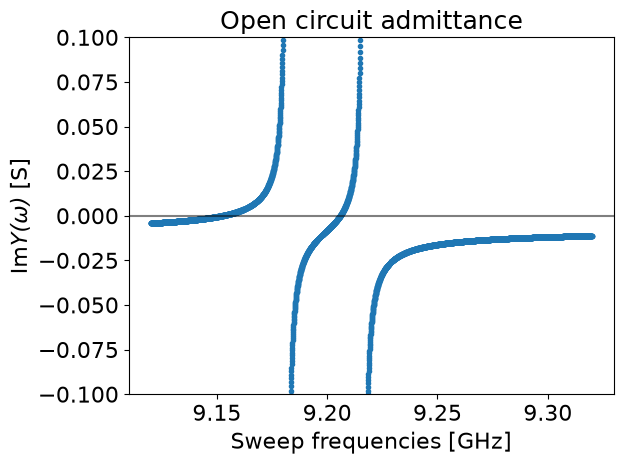

In [13]:
bbq_am_two.run()

# Fitting three modes

In [14]:
ljs = np.logspace(np.log10(1e-2 * 1e-9), np.log10(1e4 * 1e-9), 200)
bbq_am_three = BlackBoxAdmittanceModel(admittance_filename="../../data/ydata_open_circuit_mumachined_degenerate_with_coupler.csv",
                                ljs=ljs, n_modes=3)

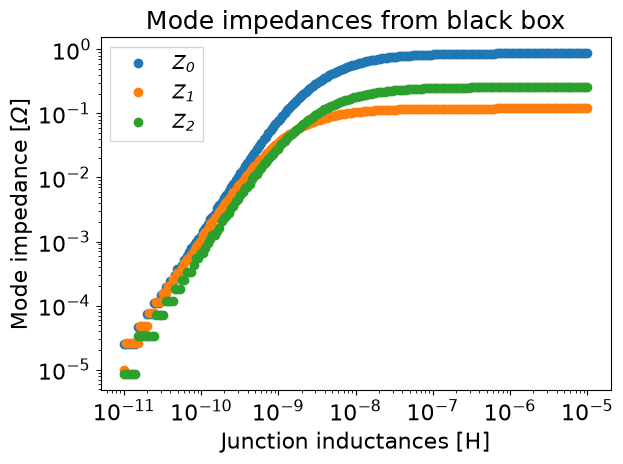

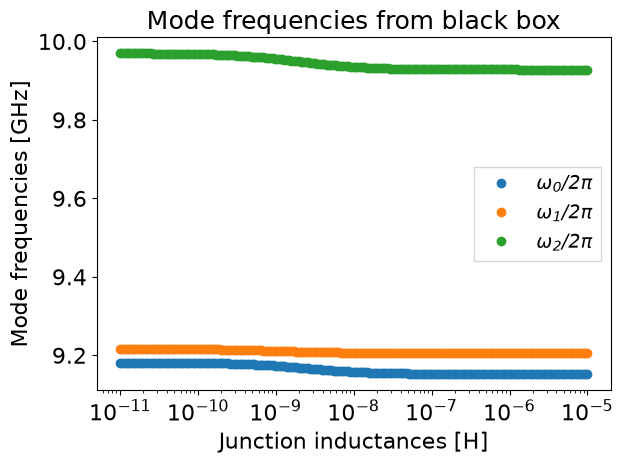

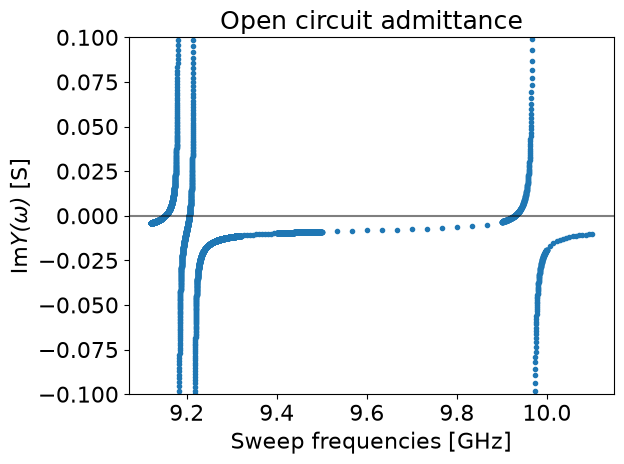

In [15]:
bbq_am_three.run()

## Fit the mode impedances

In [27]:
mode_index = 0
unit_scale = 1e9
zp = bbq_am_three.mode_impedances[:, mode_index]
zps = bbq_am_three.mode_impedances
wps = bbq_am_three.mode_frequencies / unit_scale
circ_model = TwoCavityOneCouplerModel(data=zps, x=ljs * unit_scale, unit_scale=unit_scale, wp_data=wps)

In [28]:
fit_result = circ_model.minimize() # method="differential_evolution")

Negative eigenvalue detected: wsq[wsq < 0] = array([-0.01001001])
[[ 2.38434716e-03  0.00000000e+00 -3.17338702e-04]
 [ 0.00000000e+00  1.23369234e+01 -2.81714881e+00]
 [-3.17338702e-04 -2.81714881e+00  6.32775331e-01]]
Negative eigenvalue detected: wsq[wsq < 0] = array([-0.03840038])
[[ 2.38434716e-03  0.00000000e+00 -3.17338702e-04]
 [ 0.00000000e+00  1.23369234e+01 -2.81714881e+00]
 [-3.17338702e-04 -2.81714881e+00  6.02904695e-01]]
Negative eigenvalue detected: wsq[wsq < 0] = array([-0.06489651])
[[ 2.38434716e-03  0.00000000e+00 -3.17338702e-04]
 [ 0.00000000e+00  1.23369234e+01 -2.81714881e+00]
 [-3.17338702e-04 -2.81714881e+00  5.75037471e-01]]
Negative eigenvalue detected: wsq[wsq < 0] = array([-0.08962104])
[[ 2.38434716e-03  0.00000000e+00 -3.17338702e-04]
 [ 0.00000000e+00  1.23369234e+01 -2.81714881e+00]
 [-3.17338702e-04 -2.81714881e+00  5.49039291e-01]]
Negative eigenvalue detected: wsq[wsq < 0] = array([-0.1126918])
[[ 2.38434716e-03  0.00000000e+00 -3.17338702e-04]
 [ 0

In [29]:
fit_result.params

name,value,standard error,relative error,initial value,min,max,vary
l1,5.72226886,4992.97492,(87255.16%),0.1,0.10000000,2000.00000,True
l2,2.25761158,680.923927,(30161.25%),0.3,0.10000000,2000.00000,True
l1c,1999.99986,4935637.61,(246781.90%),0.1,0.10000000,2000.00000,True
l2c,1.91560820,109.569699,(5719.84%),0.1,0.10000000,2000.00000,True
c1,1.38491176,1128.31854,(81472.23%),0.3,1.0000e-04,2.00000000,True
c2,1.67457377,505.745009,(30201.42%),0.1,1.0000e-04,2.00000000,True
cj,1.99999990,1.75615104,(87.81%),0.002,1.0000e-04,2.00000000,True


params = Parameters([('l1', <Parameter 'l1', value=5.722268863224888 +/- 4.99e+03, bounds=[0.1:2000]>), ('l2', <Parameter 'l2', value=2.2576115801658783 +/- 681, bounds=[0.1:2000]>), ('l1c', <Parameter 'l1c', value=1999.9998576853584 +/- 4.94e+06, bounds=[0.1:2000]>), ('l2c', <Parameter 'l2c', value=1.9156082040206008 +/- 110, bounds=[0.1:2000]>), ('c1', <Parameter 'c1', value=1.3849117552524577 +/- 1.13e+03, bounds=[0.0001:2.0]>), ('c2', <Parameter 'c2', value=1.6745737737058286 +/- 506, bounds=[0.0001:2.0]>), ('cj', <Parameter 'cj', value=1.999999896390409 +/- 1.76, bounds=[0.0001:2.0]>)])


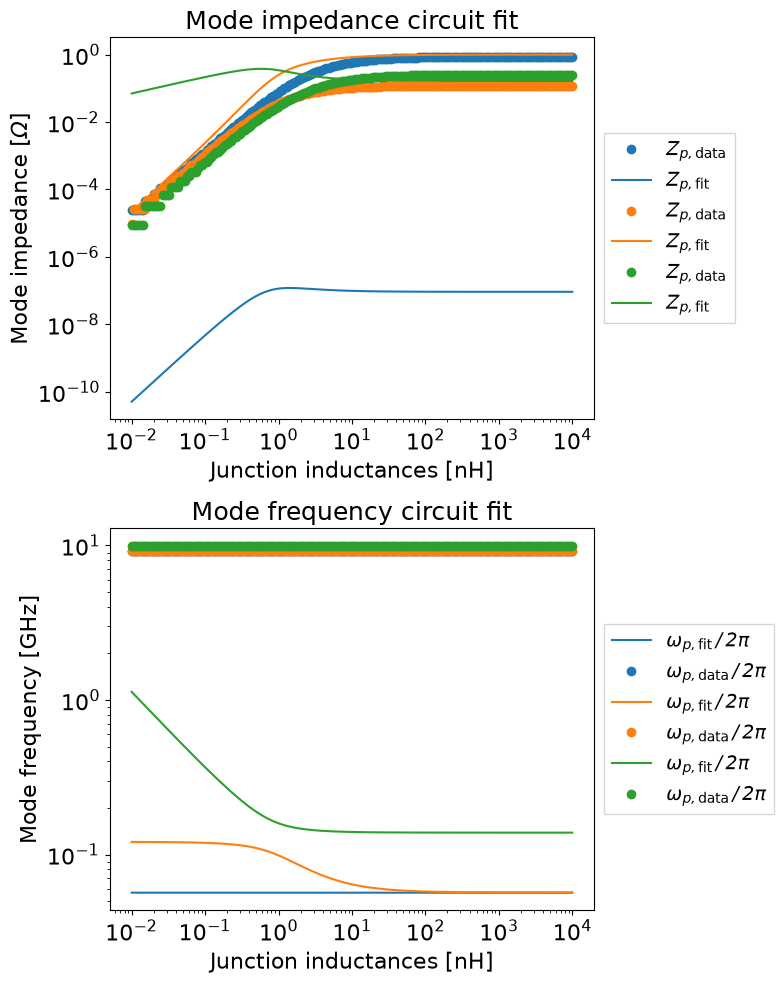

In [37]:
circ_model.plot_fit(params=fit_result.params)

In [ ]:
params = circ_model.guess(zp, x=ljs * unit_scale)
fit_result = circ_model.fit(zp, x=ljs * unit_scale, params=params, )

In [ ]:
fit_result.params

In [ ]:
fit_result.plot_fit()